## Set Up and Config

In [8]:
import os, json, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import exchange_calendars as excal
import pytz
import math
import time
from datetime import datetime, timedelta, time as dt_time
from IPython.display import display, Markdown
from dotenv import load_dotenv

load_dotenv()

# ===== Configuration =====
API_KEY_ID     = os.environ.get("API_KEY_ID")
API_SECRET_KEY = os.environ.get("API_SECRET_KEY")

nyc_tz = pytz.timezone("America/New_York")

TICKER     = "TQQQ"
START_DATE = "2016-01-01"
END_DATE   = "2026-04-20"

orb_m      = 5             # Opening range (minutes)
target_R_HL  = 10          # H/L mode: profit target at 10x stop distance
target_R_ATR = float('inf')  # ATR mode: no profit target (hold to close)
commission = 0.0005        # Per-share commission
risk       = 0.01          # Equity risk per trade
max_Lev    = 4             # Max leverage
AUM_0      = 25000         # Starting capital
stop_atr   = 0.05          # ATR stop multiplier (fraction of ATR%)

ACTIVE_PROVIDERS = ["Alpaca"]

## Getting the data

In [9]:
ALP_INTRADAY = f"data/alpaca/{TICKER}_intraday.csv"
ALP_DAILY    = f"data/alpaca/{TICKER}_daily.csv"

def get_alpaca_data(symbol=TICKER, timeframe="1Min",
                    start_date=START_DATE, end_date=END_DATE,
                    max_retries=5, delay=0.35):
    base_url = "https://data.alpaca.markets/v2/stocks/bars"
    headers = {"APCA-API-KEY-ID": API_KEY_ID, "APCA-API-SECRET-KEY": API_SECRET_KEY}
    params = {
        "symbols": symbol, "timeframe": timeframe,
        "start": datetime.strptime(start_date, "%Y-%m-%d").isoformat() + "Z",
        "end": (datetime.strptime(end_date, "%Y-%m-%d") + timedelta(days=1)).isoformat() + "Z",
        "limit": 10000, "adjustment": "raw", "feed": "sip",
    }
    all_results = []
    batch = 0
    while True:
        batch += 1
        for attempt in range(max_retries):
            try:
                response = requests.get(base_url, headers=headers, params=params, timeout=30)
                if response.status_code == 429:
                    wait = int(response.headers.get("Retry-After", 2 ** attempt))
                    print(f"  Rate limited, waiting {wait}s...")
                    time.sleep(wait)
                    continue
                if response.status_code != 200:
                    print(f"Error {response.status_code}: {response.text}")
                    if attempt < max_retries - 1:
                        time.sleep(2 ** attempt)
                        continue
                    raise RuntimeError(f"API returned {response.status_code} after {max_retries} retries. "
                                       f"Downloaded {len(all_results):,} bars before failure.")
                break
            except (requests.exceptions.ConnectionError, requests.exceptions.Timeout) as e:
                if attempt < max_retries - 1:
                    wait = 2 ** (attempt + 1)
                    print(f"  Batch {batch} attempt {attempt+1} failed ({type(e).__name__}), retrying in {wait}s...")
                    time.sleep(wait)
                else:
                    raise RuntimeError(f"Batch {batch} failed after {max_retries} attempts. "
                                       f"Downloaded {len(all_results):,} bars before failure. "
                                       f"Delete the cached CSV and re-run.")
        data = response.json()
        bars = data.get("bars", {})
        batch_results = []
        for sym, entries in bars.items():
            for entry in entries:
                entry["symbol"] = sym
                batch_results.append(entry)
        if not batch_results:
            break
        if batch % 10 == 1:
            print(f"  Batch {batch}: {len(batch_results)} bars (total: {len(all_results):,})")
        all_results.extend(batch_results)
        npt = data.get("next_page_token")
        if not npt:
            break
        params["page_token"] = npt
        time.sleep(delay)
    print(f"  Downloaded {len(all_results):,} bars in {batch} batches")
    return all_results


def process_alpaca_intraday(results):
    df = pd.DataFrame(results)
    df["datetime_utc"] = pd.to_datetime(df["t"])
    df["datetime_et"] = df["datetime_utc"].dt.tz_convert(nyc_tz)
    df["caldt"] = df["datetime_et"].dt.tz_localize(None)
    df = df.set_index("datetime_et")
    df = df.between_time("09:30", "15:59").reset_index()
    df["date"] = df["datetime_et"].dt.date
    df = df.rename(columns={"v": "volume", "o": "open", "c": "close", "h": "high", "l": "low", "t": "timestamp_iso"})
    df["day"] = df["date"]
    df["vwap"] = np.nan
    df["timestamp_ms"] = df["datetime_utc"].astype(np.int64) // 10**6
    df["transactions"] = np.nan
    cols = ["datetime_et", "volume", "vwap", "open", "close", "high", "low",
            "timestamp_ms", "transactions", "datetime_utc", "caldt", "date", "day"]
    return df[cols]


def download_daily_alpaca(ticker, start_date, end_date):
    atr_start = (datetime.strptime(start_date, "%Y-%m-%d") - timedelta(days=45)).strftime("%Y-%m-%d")
    base_url = "https://data.alpaca.markets/v2/stocks/bars"
    headers = {"APCA-API-KEY-ID": API_KEY_ID, "APCA-API-SECRET-KEY": API_SECRET_KEY}
    all_bars = []
    page_token = None
    while True:
        params = {"symbols": ticker, "timeframe": "1Day", "start": atr_start,
                  "end": (datetime.strptime(end_date, "%Y-%m-%d") + timedelta(days=1)).strftime("%Y-%m-%d"),
                  "limit": 10000, "adjustment": "all", "feed": "sip"}
        if page_token:
            params["page_token"] = page_token
        resp = requests.get(base_url, headers=headers, params=params, timeout=30)
        if resp.status_code == 429:
            time.sleep(int(resp.headers.get("Retry-After", 5)))
            continue
        if resp.status_code != 200:
            raise Exception(f"Alpaca error {resp.status_code}: {resp.text}")
        body = resp.json()
        bars = body.get("bars", {}).get(ticker, [])
        all_bars.extend(bars)
        page_token = body.get("next_page_token")
        if not page_token:
            break
        time.sleep(0.35)
    df = pd.DataFrame(all_bars)
    df["day"] = pd.to_datetime(df["t"]).dt.tz_convert(nyc_tz).dt.date
    df = df.rename(columns={"o": "open", "h": "high", "l": "low", "c": "close"})
    return df[["day", "open", "high", "low", "close"]].drop_duplicates(subset="day").sort_values("day").reset_index(drop=True)


if os.path.exists(ALP_INTRADAY):
    print(f"Alpaca intraday cached: {ALP_INTRADAY}")
else:
    print("Downloading Alpaca intraday data...")
    raw = get_alpaca_data()
    alpaca_intra = process_alpaca_intraday(raw)
    alpaca_intra.to_csv(ALP_INTRADAY, index=False)
    print(f"Saved {len(alpaca_intra):,} bars to {ALP_INTRADAY}")

if os.path.exists(ALP_DAILY):
    print(f"Alpaca daily cached: {ALP_DAILY}")
else:
    print("Downloading Alpaca daily data (fully adjusted: splits + dividends)...")
    alp_daily = download_daily_alpaca(TICKER, START_DATE, END_DATE)
    alp_daily.to_csv(ALP_DAILY, index=False)
    print(f"Saved {len(alp_daily)} rows to {ALP_DAILY}")

  Batch 1: 10000 bars (total: 0)
  Batch 11: 10000 bars (total: 100,000)
  Batch 21: 10000 bars (total: 200,000)
  Batch 31: 10000 bars (total: 300,000)
  Batch 41: 10000 bars (total: 400,000)
  Batch 51: 10000 bars (total: 500,000)
  Batch 61: 10000 bars (total: 600,000)
  Batch 71: 10000 bars (total: 700,000)
  Batch 81: 10000 bars (total: 800,000)
  Batch 91: 10000 bars (total: 900,000)
  Batch 101: 10000 bars (total: 1,000,000)
  Batch 111: 10000 bars (total: 1,100,000)
  Batch 121: 10000 bars (total: 1,200,000)
  Batch 131: 10000 bars (total: 1,300,000)
  Batch 141: 10000 bars (total: 1,400,000)
  Batch 151: 10000 bars (total: 1,500,000)
  Batch 161: 10000 bars (total: 1,600,000)
  Batch 171: 10000 bars (total: 1,700,000)
  Batch 181: 10000 bars (total: 1,800,000)
  Batch 191: 10000 bars (total: 1,900,000)
  Downloaded 1,942,444 bars in 195 batches
Saved 980,480 bars to data/alpaca/TQQQ_intraday.csv
Saved 2589 rows to data/alpaca/TQQQ_daily.csv


## Formatting the data and computing ATR%

In [10]:
alpaca_df    = pd.read_csv(ALP_INTRADAY, parse_dates=["caldt", "day"])
alpaca_days    = pd.DatetimeIndex(sorted(alpaca_df["day"].unique()))

datasets = {
    "Alpaca":   (alpaca_df,    alpaca_days),
}

print("Dataset Summary:")
print(f"{'Provider':<12} {'Bars':>10} {'Start':<28} {'End':<28}")
print("-" * 80)
for name, (df, _) in datasets.items():
    print(f"{name:<12} {len(df):>10,} {str(df['datetime_et'].min()):<28} {str(df['datetime_et'].max()):<28}")

# --- Compute ATR% lookups ---

def compute_atr_pct_lookup(daily_df, period=14):
    """Return {date: atr_pct} where atr_pct = ATR(14) / daily_open, lagged by 1 day."""
    df = daily_df.sort_values("day").reset_index(drop=True)
    high_low = df["high"] - df["low"]
    high_close = np.abs(df["high"] - df["close"].shift(1))
    low_close = np.abs(df["low"] - df["close"].shift(1))
    ranges = pd.concat([high_low, high_close, low_close], axis=1)
    true_range = ranges.max(axis=1)
    atr = true_range.rolling(window=period, min_periods=period).mean()
    atr_pct = atr / df["open"]
    df["atr_pct_lag"] = atr_pct.shift(1)
    return dict(zip(df["day"], df["atr_pct_lag"]))


def load_daily_csv(path):
    df = pd.read_csv(path)
    df["day"] = pd.to_datetime(df["day"]).dt.date
    return df


daily_sources = {
    "Alpaca":   ALP_DAILY,
}

atr_pct_lookups = {}
for name, path in daily_sources.items():
    if os.path.exists(path):
        ddf = load_daily_csv(path)
        atr_pct_lookups[name] = compute_atr_pct_lookup(ddf)
        print(f"  {name:>10s}: ATR% lookup ready ({len(atr_pct_lookups[name])} days) from {path}")
    else:
        print(f"  {name:>10s}: daily file not found at {path}")

provider_atr_pct_map = {}
for name in datasets:
    if name in atr_pct_lookups:
        provider_atr_pct_map[name] = atr_pct_lookups[name]

print(f"\nATR% lookups assigned for {len(provider_atr_pct_map)} providers")

print("\nATR% coverage (first -> last valid date):")
for name, lookup in atr_pct_lookups.items():
    valid = sorted([d for d, v in lookup.items() if v is not None and not np.isnan(v)])
    if valid:
        print(f"  {name:>10s}: {valid[0]} to {valid[-1]}  ({len(valid)} days)")
    else:
        print(f"  {name:>10s}: NO valid ATR%!")

Dataset Summary:
Provider           Bars Start                        End                         
--------------------------------------------------------------------------------
Alpaca          980,480 2016-01-04 09:31:00-04:56    2026-04-20 15:59:00-04:56   
      Alpaca: ATR% lookup ready (2589 days) from data/alpaca/TQQQ_daily.csv

ATR% lookups assigned for 1 providers

ATR% coverage (first -> last valid date):
      Alpaca: 2016-01-25 to 2026-04-20  (2575 days)


## Filter out early-close days

In [11]:
nyse = excal.get_calendar("XNYS")
nyse_sessions = nyse.sessions_in_range("2015-01-01", nyse.last_session)
nyse_close_utc = nyse.schedule.loc[nyse_sessions, "close"]
nyse_close_et = nyse_close_utc.dt.tz_convert("US/Eastern")
early_dates = set(nyse.early_closes.date)

ec_close_map = {}
for sess, close_t in zip(nyse_sessions, nyse_close_et):
    if sess.date() in early_dates:
        ec_close_map[sess.date()] = close_t.hour * 60 + close_t.minute

print(f"Early-close days in calendar: {len(ec_close_map)}\n")

for name in list(datasets.keys()):
    df, days = datasets[name]

    bar_minutes = df["caldt"].dt.hour * 60 + df["caldt"].dt.minute
    bar_date = df["day"].dt.date

    close_thresh = bar_date.map(ec_close_map)
    is_early_day = close_thresh.notna()
    close_thresh = close_thresh.fillna(960).astype(int)

    remove = is_early_day & (bar_minutes >= close_thresh)

    n_removed = remove.sum()
    if n_removed > 0:
        affected = df[remove].groupby(df[remove]["day"].dt.date).size()
        df_filtered = df[~remove].reset_index(drop=True)
        days_filtered = pd.DatetimeIndex(sorted(df_filtered["day"].unique()))
        datasets[name] = (df_filtered, days_filtered)
        print(f"  {name:>10s}: removed {n_removed:>5d} bars across {len(affected)} early-close days")
    else:
        print(f"  {name:>10s}: clean")

alpaca_df, alpaca_days = datasets["Alpaca"]

print(f"\nFiltered bar counts:")
for name, (df, _) in datasets.items():
    print(f"  {name:>10s}: {len(df):>10,} bars")

Early-close days in calendar: 25

      Alpaca: removed  2109 bars across 21 early-close days

Filtered bar counts:
      Alpaca:    978,371 bars


## Backtest Engine

In [12]:
def backtest(days, p, orb_m, target_R, risk, max_Lev, AUM_0, commission,
             stop_type="HL", stop_atr=0.075, atr_pct_lookup=None):
    """Run the ORB backtest on a given dataset.

    stop_type:       "HL" = opening-range high/low stop, "ATR" = ATR-based stop
    stop_atr:        fraction multiplier applied to ATR% (e.g. 0.05 = 5% of ATR)
    atr_pct_lookup:  pre-computed {date: atr_pct} dict where atr_pct = ATR(14) / daily_open.

    When stop_type="ATR", the stop width in dollars is:
        stop_width_$ = stop_atr * atr_pct * intraday_open / entry
    This is a fractional distance from entry (e.g. 0.02 means $2 on a $100 entry).
    """
    start_time = time.time()
    str_df = pd.DataFrame()
    str_df['Date'] = days
    str_df['AUM'] = np.nan
    str_df.loc[0, 'AUM'] = AUM_0
    str_df['pnl_R'] = np.nan
    or_candles = orb_m
    day_groups = dict(tuple(p.groupby(p['day'].dt.date)))

    if stop_type == "ATR" and atr_pct_lookup is None:
        raise ValueError("atr_pct_lookup is required when stop_type='ATR'. "
                         "Pre-compute it with compute_atr_pct_lookup().")

    for t in range(1, len(days)):
        current_day = days[t].date()
        if current_day not in day_groups:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        day_data = day_groups[current_day]
        if len(day_data) <= or_candles:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        OHLC = day_data[['open', 'high', 'low', 'close']].values
        side = np.sign(OHLC[or_candles-1, 3] - OHLC[0, 0])
        entry = OHLC[or_candles, 0] if len(OHLC) > or_candles else np.nan

        if stop_type == "ATR":
            atr_pct_d = atr_pct_lookup.get(current_day, np.nan)
            intra_open = OHLC[0, 0]
            stop = stop_atr * atr_pct_d * intra_open / entry if not np.isnan(atr_pct_d) else np.nan
        else:
            if side == 1:
                stop = abs(np.min(OHLC[:or_candles, 2]) / entry - 1)
            elif side == -1:
                stop = abs(np.max(OHLC[:or_candles, 1]) / entry - 1)
            else:
                stop = np.nan

        if side == 0 or np.isnan(stop) or np.isnan(entry):
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        if entry == 0 or stop == 0:
            shares = 0
        else:
            shares = math.floor(min(str_df.loc[t-1, 'AUM'] * risk / (entry * stop),
                                    max_Lev * str_df.loc[t-1, 'AUM'] / entry))

        if shares == 0:
            str_df.loc[t, 'pnl_R'] = 0
            str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM']
            continue

        OHLC_post_entry = OHLC[or_candles:, :]

        if side == 1:
            stop_price = entry * (1 - stop)
            target_price = entry * (1 + target_R * stop) if np.isfinite(target_R) else float('inf')
            stop_hits = OHLC_post_entry[:, 2] <= stop_price
            target_hits = OHLC_post_entry[:, 1] >= target_price

            if np.any(stop_hits) and np.any(target_hits):
                idx_stop = np.argmax(stop_hits)
                idx_target = np.argmax(target_hits)
                if idx_target < idx_stop:
                    PnL_T = max(target_price, OHLC_post_entry[idx_target, 0]) - entry
                else:
                    PnL_T = min(stop_price, OHLC_post_entry[idx_stop, 0]) - entry
            elif np.any(stop_hits):
                idx_stop = np.argmax(stop_hits)
                PnL_T = min(stop_price, OHLC_post_entry[idx_stop, 0]) - entry
            elif np.any(target_hits):
                idx_target = np.argmax(target_hits)
                PnL_T = max(target_price, OHLC_post_entry[idx_target, 0]) - entry
            else:
                PnL_T = OHLC_post_entry[-1, 3] - entry

        elif side == -1:
            stop_price = entry * (1 + stop)
            target_price = entry * (1 - target_R * stop) if np.isfinite(target_R) else 0
            stop_hits = OHLC_post_entry[:, 1] >= stop_price
            target_hits = OHLC_post_entry[:, 2] <= target_price

            if np.any(stop_hits) and np.any(target_hits):
                idx_stop = np.argmax(stop_hits)
                idx_target = np.argmax(target_hits)
                if idx_target < idx_stop:
                    PnL_T = entry - min(target_price, OHLC_post_entry[idx_target, 0])
                else:
                    PnL_T = entry - max(stop_price, OHLC_post_entry[idx_stop, 0])
            elif np.any(stop_hits):
                idx_stop = np.argmax(stop_hits)
                PnL_T = entry - max(stop_price, OHLC_post_entry[idx_stop, 0])
            elif np.any(target_hits):
                idx_target = np.argmax(target_hits)
                PnL_T = entry - min(target_price, OHLC_post_entry[idx_target, 0])
            else:
                PnL_T = entry - OHLC_post_entry[-1, 3]

        str_df.loc[t, 'AUM'] = str_df.loc[t-1, 'AUM'] + shares * PnL_T - shares * commission * 2
        str_df.loc[t, 'pnl_R'] = (str_df.loc[t, 'AUM'] - str_df.loc[t-1, 'AUM']) / (risk * str_df.loc[t-1, 'AUM'])

    elapsed = round(time.time() - start_time, 2)
    final_aum = str_df['AUM'].iloc[-1]
    total_ret = (final_aum / AUM_0 - 1) * 100
    print(f"  Completed in {elapsed}s | Final AUM: ${final_aum:,.2f} | Return: {total_ret:.1f}%")
    return str_df

## Performance Analysis Utils

In [13]:
def price2return(price, n=1):
    price = np.array(price)
    T = len(price)
    y = np.full_like(price, np.nan, dtype=float)
    if T > n:
        y[n:] = price[n:] / price[:T-n] - 1
    return y

def summary_statistics(dailyReturns):
    tradingDays = 252
    dailyReturns = np.array(dailyReturns)
    dailyReturns = dailyReturns[~np.isnan(dailyReturns)]
    totalReturn = np.prod(1 + dailyReturns) - 1
    numYears = len(dailyReturns) / tradingDays
    CAGR = (1 + totalReturn)**(1/numYears) - 1
    volatility = np.std(dailyReturns, ddof=0) * np.sqrt(tradingDays)
    sharpeRatio = (np.mean(dailyReturns)) / np.std(dailyReturns, ddof=0) * np.sqrt(tradingDays)
    nav = np.cumprod(1 + dailyReturns)
    peak = np.maximum.accumulate(nav)
    drawdown = (nav - peak) / peak
    MDD = np.min(drawdown)
    metrics = ["Total Return (%)", "CAGR (%)", "Volatility (%)", "Sharpe Ratio", "Max Drawdown (%)"]
    values = [totalReturn*100, CAGR*100, volatility*100, sharpeRatio, MDD*100]
    formatted = [f"{v:.2f}" for v in values]
    return pd.DataFrame({'Metric': metrics, 'Value': formatted})

def monthly_performance_table(returns, dates):
    returns_series = pd.Series(returns, index=pd.DatetimeIndex(dates))
    returns_series = returns_series[~np.isnan(returns_series)]
    df = pd.DataFrame({'return': returns_series,
                       'year': returns_series.index.year,
                       'month': returns_series.index.month})
    monthly = df.groupby(['year', 'month'])['return'].apply(lambda x: np.prod(1 + x) - 1).reset_index()
    pivot = monthly.pivot(index='year', columns='month', values='return')
    pivot['Year Total'] = pivot.apply(lambda row: np.prod(1 + row.dropna()) - 1
                                       if not row.dropna().empty else np.nan, axis=1)
    formatted = pivot.apply(lambda col: col.map(lambda x: f"{x*100:.2f}%" if not pd.isna(x) else ""))
    month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                   7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
    return formatted.rename(columns=month_names)

def plot_equity_curves(all_results, AUM_0, orb_m, ticker,
                       target_R_HL=10, target_R_ATR=float('inf'),
                       stop_atr=None, oos_date=None):
    stop_colors = {'HL': '#e74c3c', 'ATR': '#3498db'}
    hl_tgt = f"{target_R_HL}R" if np.isfinite(target_R_HL) else "NoTgt"
    atr_tgt = f"{target_R_ATR}R" if np.isfinite(target_R_ATR) else "NoTgt"
    stop_labels = {
        'HL': f'H/L {hl_tgt}',
        'ATR': f'{stop_atr*100:.1f}% ATR {atr_tgt}' if stop_atr else f'ATR {atr_tgt}'
    }

    fig, ax = plt.subplots(figsize=(12, 7))

    oos_ts = pd.Timestamp(oos_date) if oos_date is not None else None

    all_aum = []
    for stop_type, results in all_results.items():
        for name, result_df in results.items():
            df_clean = result_df.dropna(subset=['Date', 'AUM'])
            weekly = df_clean.set_index('Date')['AUM'].resample('W').last().dropna()
            if len(weekly) == 0:
                continue
            all_aum.extend(weekly.values)
            final_aum = weekly.values[-1]
            n_days = len(df_clean)
            cagr = (final_aum / AUM_0) ** (252 / max(n_days, 1)) - 1
            c = stop_colors.get(stop_type, 'gray')
            ax.plot(weekly.index, weekly.values, linewidth=1.8, color=c,
                    label=f"{stop_labels[stop_type]}  CAGR {cagr*100:.1f}%")

    ax.set_yscale('log', base=2)

    y_min = min(all_aum) if all_aum else AUM_0
    y_max = max(all_aum) if all_aum else AUM_0 * 2

    tick_val = AUM_0
    ticks_up = []
    while tick_val <= y_max * 2:
        ticks_up.append(tick_val)
        tick_val *= 2

    tick_val = AUM_0 / 2
    ticks_down = []
    while tick_val >= y_min * 0.7:
        ticks_down.append(tick_val)
        tick_val /= 2

    ticks = sorted(set(ticks_down + ticks_up))
    ax.set_yticks(ticks)
    ax.set_yticklabels([f'${v:,.0f}' for v in ticks])
    ax.set_ylim(bottom=ticks[0] * 0.85, top=ticks[-1] * 1.15)
    ax.minorticks_off()

    if oos_ts is not None and len(all_aum) > 0:
        last_date = max(r.dropna(subset=['Date'])['Date'].max()
                        for res in all_results.values() for r in res.values())
        ax.axvspan(oos_ts, last_date, alpha=0.1, color='green', label='Out-of-Sample')
        ax.axvline(oos_ts, color='black', linewidth=1.2, linestyle='--', alpha=0.7)

    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.xticks(rotation=90)
    ax.grid(True, linestyle=':', alpha=0.5)

    ax.set_title(f"{orb_m}m-ORB  |  {ticker}",
                 fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=10, framealpha=0.9)
    ax.set_ylabel("Account Value")

    plt.tight_layout()
    plt.show()
    return fig, ax

## Run both backtests

In [14]:
bt_start = pd.Timestamp(START_DATE) if START_DATE else None
bt_end   = pd.Timestamp(END_DATE)   if END_DATE   else None

# --- Build per-provider day sets within the requested window ---
provider_filtered_days = {}
for name, (df, days) in datasets.items():
    if name not in ACTIVE_PROVIDERS:
        continue
    fd = days
    if bt_start is not None:
        fd = fd[fd >= bt_start]
    if bt_end is not None:
        fd = fd[fd <= bt_end]
    provider_filtered_days[name] = fd

for name, fd in provider_filtered_days.items():
    print(f"  {name}: {len(fd)} trading days")

# --- Run backtests ---
all_results = {}
for stop_type in ["HL", "ATR"]:
    target_R = target_R_HL if stop_type == "HL" else target_R_ATR
    target_str = f"Target {target_R}R" if np.isfinite(target_R) else "No Target"
    stop_label = "Stop H/L" if stop_type == "HL" else f"Stop {stop_atr*100:.1f}% ATR"
    print(f"\n{'='*60}")
    print(f"  {stop_label}  |  {target_str}")
    print(f"{'='*60}")
    results = {}
    for name, (df, days) in datasets.items():
        if name not in ACTIVE_PROVIDERS:
            continue
        filtered_days = provider_filtered_days[name]
        print(f"  {name} ({len(filtered_days)} days)...")
        results[name] = backtest(filtered_days, df, orb_m, target_R, risk, max_Lev, AUM_0, commission,
                                 stop_type=stop_type, stop_atr=stop_atr,
                                 atr_pct_lookup=provider_atr_pct_map[name] if stop_type == "ATR" else None)
    all_results[stop_type] = results

  Alpaca: 2588 trading days

  Stop H/L  |  Target 10R
  Alpaca (2588 days)...
  Completed in 3.32s | Final AUM: $770,675.19 | Return: 2982.7%

  Stop 5.0% ATR  |  No Target
  Alpaca (2588 days)...
  Completed in 2.53s | Final AUM: $843,412.71 | Return: 3273.7%


## Results
### Equity Curves

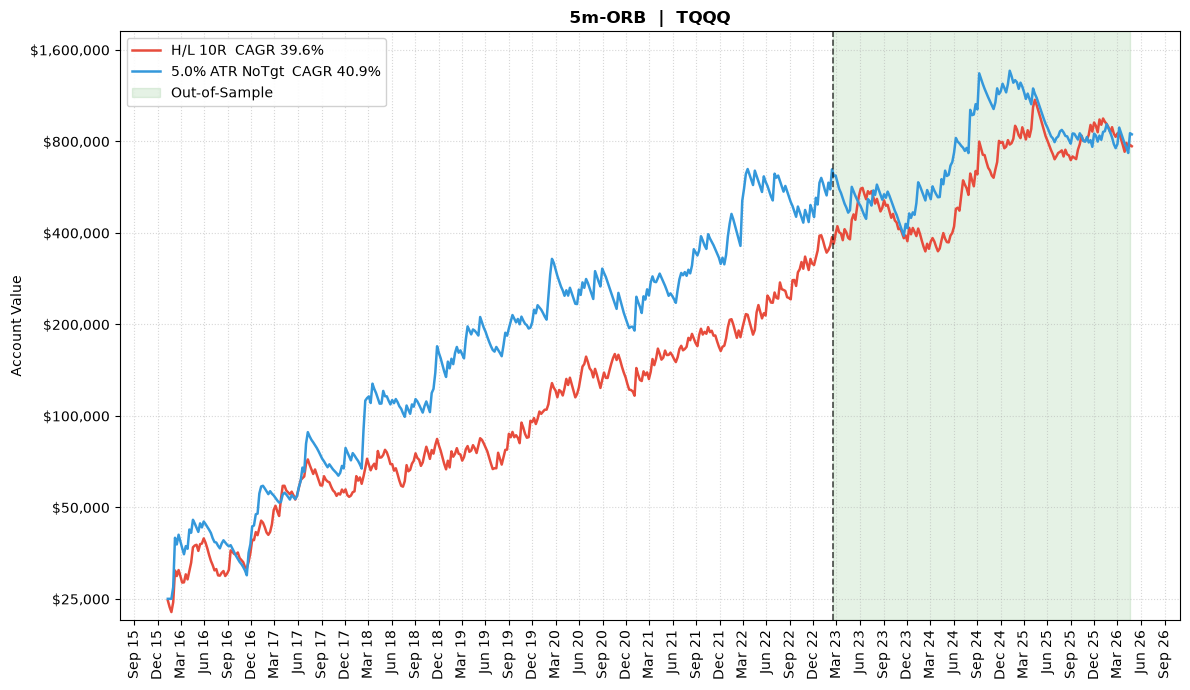

In [15]:
OOS_DATE = "2023-02-17"

plot_equity_curves(all_results, AUM_0, orb_m, TICKER,
                   target_R_HL=target_R_HL, target_R_ATR=target_R_ATR,
                   stop_atr=stop_atr, oos_date=OOS_DATE);

### Performance summary

In [16]:
for stop_type, results in all_results.items():
    stop_label = f"Stop {stop_atr*100:.1f}% ATR" if stop_type == "ATR" else "Stop H/L"
    display(Markdown(f"#### {stop_label}"))
    summary_rows = []
    for name, result_df in results.items():
        returns = price2return(result_df['AUM'].values)
        if len(returns) == 0:
            continue
        stats = summary_statistics(returns)
        row = {m: v for m, v in zip(stats['Metric'], stats['Value'])}
        row['Provider'] = name
        summary_rows.append(row)
    display(pd.DataFrame(summary_rows).set_index('Provider'))

#### Stop H/L

,Total Return (%),CAGR (%),Volatility (%),Sharpe Ratio,Max Drawdown (%)
Provider,,,,,
Alpaca,2982.70,39.65,41.48,1.00,-41.00


#### Stop 5.0% ATR

,Total Return (%),CAGR (%),Volatility (%),Sharpe Ratio,Max Drawdown (%)
Provider,,,,,
Alpaca,3273.65,40.88,53.54,0.88,-47.43


### Monthly returns

In [17]:
for stop_type, results in all_results.items():
    stop_label = f"Stop {stop_atr*100:.1f}% ATR" if stop_type == "ATR" else "Stop H/L"
    display(Markdown(f"### {stop_label}"))
    for name, result_df in results.items():
        returns = price2return(result_df['AUM'].values)
        if len(returns) == 0:
            continue
        display(Markdown(f"#### {name}"))
        display(monthly_performance_table(returns, result_df['Date']))

### Stop H/L

#### Alpaca

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year Total
year,,,,,,,,,,,,,
2016,-2.56%,20.70%,6.20%,20.59%,4.09%,-17.31%,-8.06%,0.03%,17.41%,-6.26%,11.65%,16.84%,71.19%
2017,-2.89%,20.16%,17.81%,-6.19%,-1.84%,28.16%,-8.21%,-6.96%,1.95%,-11.35%,7.51%,-2.69%,31.01%
2018,8.72%,15.55%,-5.13%,10.14%,-5.33%,-12.20%,10.26%,11.59%,-6.67%,10.75%,2.77%,-17.45%,17.72%
2019,14.77%,-5.05%,5.81%,-1.90%,5.35%,-15.09%,5.60%,23.76%,-2.10%,2.94%,8.41%,6.16%,53.37%
2020,7.80%,10.89%,-5.54%,12.14%,-3.24%,23.71%,-7.00%,-8.85%,7.89%,13.17%,-16.56%,-12.12%,15.04%
2021,11.78%,1.48%,27.01%,-2.27%,-3.61%,9.72%,4.06%,-4.74%,10.98%,-0.19%,-13.14%,18.32%,68.06%
2022,-3.95%,1.97%,2.48%,17.78%,-5.28%,17.29%,1.55%,-5.54%,20.25%,11.50%,-7.13%,27.89%,100.64%
2023,-7.04%,6.86%,5.40%,7.39%,17.39%,5.77%,-9.63%,1.84%,-11.19%,-10.10%,-5.88%,6.24%,2.59%
2024,-8.78%,-7.41%,2.21%,7.78%,12.02%,26.34%,8.49%,8.25%,14.51%,-14.06%,28.85%,0.81%,97.69%


### Stop 5.0% ATR

#### Alpaca

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year Total
year,,,,,,,,,,,,,
2016,9.24%,39.91%,10.62%,1.45%,4.03%,-11.31%,-7.37%,1.95%,-7.37%,-8.61%,16.88%,50.29%,122.22%
2017,0.76%,-3.01%,1.40%,-3.70%,2.10%,49.48%,0.56%,-11.22%,-4.13%,-7.35%,22.75%,-4.30%,35.69%
2018,-9.86%,73.93%,0.54%,0.60%,-5.72%,-4.66%,-1.01%,6.71%,-9.72%,17.18%,34.09%,-17.47%,76.26%
2019,22.31%,-1.53%,19.21%,-2.69%,1.87%,-12.93%,-3.90%,22.62%,3.75%,-0.26%,1.16%,10.98%,69.67%
2020,9.21%,23.32%,-16.58%,0.02%,2.69%,6.20%,8.28%,1.12%,-15.28%,-0.98%,-18.13%,-8.20%,-15.40%
2021,14.25%,14.20%,14.09%,-5.73%,-7.36%,19.73%,1.87%,12.69%,6.62%,2.73%,-12.79%,19.77%,104.41%
2022,7.02%,20.94%,18.53%,-1.23%,-1.30%,7.37%,-9.13%,-10.31%,-4.36%,-3.55%,-2.32%,31.89%,55.54%
2023,-5.52%,5.63%,-17.61%,13.62%,-13.01%,4.80%,2.31%,1.38%,-4.75%,-15.48%,-3.32%,9.93%,-24.42%
2024,17.45%,-3.46%,0.76%,19.88%,17.09%,5.14%,6.59%,23.71%,15.87%,-13.47%,14.52%,19.07%,203.93%
